# W2: Heston and model misspecification

Here volatility is stochastic but the hedger still uses Black–Scholes. We measure the extra error and which hedge copes best. Variance follows Heston, with κ = 2, θ = 0.04 (20% long-run volatility), ξ = 0.5 (vol of vol) and ρ = −0.7 (spot–variance correlation, so volatility tends to rise when the stock falls). Options are priced under Heston and the hedger uses BS Greeks at each option's current implied volatility, as traders do. `model_delta` uses the Heston delta instead (variance held fixed when the stock moves).

The trade, units, metrics and strategies are as in notebook 01: short one 30-day (21 trading days) ATM call, $S_0 = 100$, held to expiry. We simulate 5,000 paths on an hourly grid (6 steps a day) with variance starting at θ, and hedge the same paths 1, 2, 3 or 6 times a day.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# hedging is this project's own code, in src/hedging/
from hedging import bs, experiments, generator, hedge, worlds

pd.set_option("display.precision", 4)
# figures are saved to results/figures/
FIG = experiments.RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

## 1. Full grid

All strategies on the same paths at 4 frequencies (1, 2, 3, 6 a day) and 4 cost levels (0, 1, 5, 10 bp), with the same columns as notebook 01. We show the first five rows; the full table is in `results/w2_grid.csv`.

In [2]:
# m: the simulated market; table: one row per strategy x frequency x cost level
m, table = experiments.w2()
# writes results/w2_grid.csv
experiments.save(table, "w2_grid")
table.head()

,world,per_day,cost_bp,strategy,rmse,cvar95,mean,std,turnover
0,W2 Heston,1,0,delta,0.5757,1.3934,-0.0101,0.5756,2.4851
1,W2 Heston,1,0,delta_gamma,0.6451,1.3070,-0.0020,0.6451,2.8450
2,W2 Heston,1,0,delta_vega,0.3324,0.8462,-0.0072,0.3323,1.8782
3,W2 Heston,1,0,model_delta,0.6479,1.5167,-0.0073,0.6478,2.5432
4,W2 Heston,1,1,delta,0.5767,1.4212,-0.0350,0.5757,2.4851


## 2. Misspecification without trading costs

With free trading the only error sources are discrete rebalancing and the wrong model. `W1 delta` is the same delta hedge in W1 (from `results/w1_grid.csv`), so comparing it with W2 `delta` shows what stochastic volatility adds. Values are RMSE; the 3-a-day row is dropped because notebook 01 did not run it.

strategy,delta,delta_gamma,delta_vega,model_delta,W1 delta
per_day,,,,,
1,0.5757,0.6451,0.3324,0.6479,0.4308
2,0.4837,0.6551,0.2416,0.5632,0.3065
6,0.4071,0.6693,0.1450,0.4956,0.1777


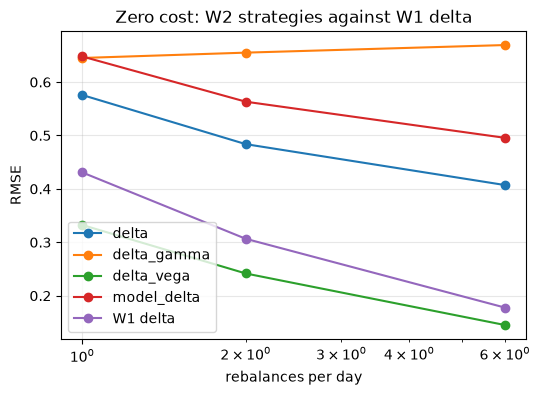

In [3]:
# notebook 01's results, for comparison
w1 = pd.read_csv(experiments.RESULTS / "w1_grid.csv")
free = table[table.cost_bp == 0].pivot(index="per_day", columns="strategy", values="rmse")
# add the zero-cost W1 delta hedge, matched by frequency
free["W1 delta"] = w1[(w1.strategy == "delta") & (w1.cost_bp == 0)].set_index("per_day").rmse
# keep only frequencies run in both worlds (W1 has no 3 a day)
free = free.dropna()
display(free)

fig, ax = plt.subplots(figsize=(6, 4))
for col in free.columns:
    ax.plot(free.index, free[col], "o-", label=col)
ax.set_xscale("log"); ax.set_xlabel("rebalances per day"); ax.set_ylabel("RMSE"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Zero cost: W2 strategies against W1 delta")
fig.savefig(FIG / "w2_misspecification.png", dpi=150, bbox_inches="tight")

Stochastic volatility more than doubles the delta-hedge error: at 6 a day, RMSE is 0.4071 in W2 against 0.1777 in W1. Rebalancing also helps less: from 1 to 6 a day the W1 error falls from 0.4308 to 0.1777 but the W2 error only from 0.5757 to 0.4071, since the volatility-driven part does not shrink with frequency.

Delta–vega removes most of the extra error (0.1450 at 6 a day, below even the W1 delta hedge). Delta–gamma stays around 0.65–0.67 at every frequency, worse than plain delta, probably because the 42-day option's gamma-to-vega ratio differs from the 30-day option's, so cancelling gamma leaves a vega position, and here vega risk is larger. The Heston delta is also worse than the Black–Scholes delta at every frequency (0.4956 against 0.4071 at 6 a day).

## 3. With trading costs

Stock trades cost 0, 1, 5 or 10 bp and the second option 1% of its price when costs are non-zero. Leland and Whalley–Wilmott are added (`NaN` at zero cost, as in notebook 01). RMSE by (cost, rebalances per day) and strategy; `whalley_wilmott` wraps below the other columns.

In [4]:
# RMSE: rows = (cost, rebalances per day), one column per strategy
table.pivot_table(index=["cost_bp", "per_day"], columns="strategy", values="rmse")

strategy          delta  delta_gamma  delta_vega  leland  model_delta  \
cost_bp per_day                                                         
0       1        0.5757       0.6451      0.3324     NaN       0.6479   
        2        0.4837       0.6551      0.2416     NaN       0.5632   
        3        0.4477       0.6582      0.1994     NaN       0.5309   
        6        0.4071       0.6693      0.1450     NaN       0.4956   
1       1        0.5767       0.6901      0.3455  0.5767       0.6479   
        2        0.4847       0.7238      0.2607  0.4847       0.5632   
        3        0.4496       0.7501      0.2281  0.4496       0.5317   
        6        0.4100       0.8221      0.1957  0.4101       0.4972   
5       1        0.5920       0.7528      0.3767  0.5912       0.6587   
        2        0.5091       0.8247      0.3134  0.5078       0.5817   
        3        0.4863       0.8837      0.3037  0.4836       0.5608   
        6        0.4723       1.0340      0.3192  0.4666       0.5487   
10      1        0.6344       0.8511      0.4354  0.6310       0.6945   
        2        0.5794       0.9808      0.4082  0.5720       0.6424   
        3        0.5839       1.0864      0.4283  0.5705       0.6463   
        6        0.6286       1.3430      0.5006  0.6008       0.6888   

strategy         whalley_wilmott  
cost_bp per_day                   
0       1                    NaN  
        2                    NaN  
        3                    NaN  
        6                    NaN  
1       1                 0.6162  
        2                 0.5329  
        3                 0.4970  
        6                 0.4583  
5       1                 0.6760  
        2                 0.5977  
        3                 0.5648  
        6                 0.5273  
10      1                 0.7302  
        2                 0.6564  
        3                 0.6272  
        6                 0.5923

The same layout for CVaR 95%.

In [5]:
# CVaR 95%, same layout
table.pivot_table(index=["cost_bp", "per_day"], columns="strategy", values="cvar95")

strategy          delta  delta_gamma  delta_vega  leland  model_delta  \
cost_bp per_day                                                         
0       1        1.3934       1.3070      0.8462     NaN       1.5167   
        2        1.1315       1.3337      0.6092     NaN       1.2559   
        3        1.0196       1.3423      0.5021     NaN       1.1520   
        6        0.9059       1.3772      0.3537     NaN       1.0489   
1       1        1.4212       1.5276      0.9240  1.4178       1.5426   
        2        1.1667       1.6359      0.7061  1.1625       1.2888   
        3        1.0594       1.6991      0.6095  1.0552       1.1878   
        6        0.9562       1.8832      0.5000  0.9521       1.0935   
5       1        1.5344       1.6836      1.0185  1.5154       1.6477   
        2        1.3121       1.8721      0.8347  1.2857       1.4230   
        3        1.2242       1.9934      0.7628  1.1964       1.3364   
        6        1.1661       2.3268      0.7098  1.1331       1.2815   
10      1        1.6803       1.8855      1.1424  1.6374       1.7836   
        2        1.5007       2.1777      1.0005  1.4383       1.5992   
        3        1.4421       2.3824      0.9661  1.3697       1.5388   
        6        1.4467       2.9188      0.9835  1.3515       1.5402   

strategy         whalley_wilmott  
cost_bp per_day                   
0       1                    NaN  
        2                    NaN  
        3                    NaN  
        6                    NaN  
1       1                 1.4692  
        2                 1.2392  
        3                 1.1456  
        6                 1.0327  
5       1                 1.6318  
        2                 1.4325  
        3                 1.3595  
        6                 1.2480  
10      1                 1.7826  
        2                 1.6082  
        3                 1.5420  
        6                 1.4386

Delta–vega has the lowest RMSE and CVaR 95% in every row, even though it pays 1% to trade the option. As in notebook 01, its best frequency falls as costs rise: 6 a day at 1 bp (RMSE 0.1957), 3 a day at 5 bp (0.3037) and 2 a day at 10 bp (0.4082).

The cost-aware rules help little: Leland beats plain delta by less than 0.03 in RMSE, and Whalley–Wilmott is worse than plain delta in every row except 10 bp at 6 a day. They save on trading costs, but here most of the error comes from volatility moves. Delta–gamma and the Heston delta stay worse than plain delta in RMSE in every row.